# Imagen de una foto a través de una lente (trazado de rayos en la GPU)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import optiland.backend as be
from optiland.optic import Optic
from scipy.ndimage import zoom

# trazado en la tarjeta gráfica (si no hay CUDA, usa la CPU con torch)
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
be.set_backend('torch')
be.set_device(dev)
be.set_precision('float32')      # float32 es mucho más rápido en una GPU de laptop
print('dispositivo:', torch.cuda.get_device_name(0) if dev == 'cuda' else 'CPU')

dispositivo: NVIDIA GeForce RTX 3050 Ti Laptop GPU


## Parámetros

In [2]:
archivo   = 'hoe_1_grabacion.png'
alto_px   = 602        # resolución de la foto (602 = tamaño original)
n         = 50         # rayos por pixel: más = menos granulado
lote      = 1_000_000  # rayos que se trazan a la vez (bájalo si falta memoria en la GPU)

objeto    = 150.0      # distancia objeto -> lente [mm]
pantalla  = 70.0       # distancia lente -> pantalla [mm]  (70.0 es el mejor foco con EPD=10)
EPD       = 10.0       # diámetro de la apertura [mm]      (prueba EPD=6, pantalla=70.5: más nítida)
h_obj     = 10.0       # media anchura del objeto [mm]

## Lente

/home/artis/miniconda3/envs/optica/lib/python3.14/site-packages/optiland/visualization/system/lens.py:58: UserWarning: Lens surfaces overlap.
  self._check_surface_overlap()


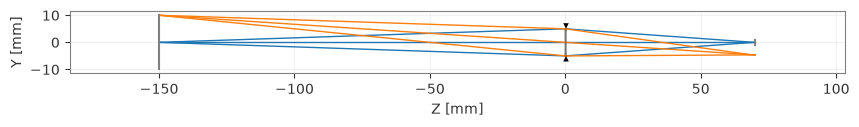

(<Figure size 1000x400 with 1 Axes>, <Axes: xlabel='Z [mm]', ylabel='Y [mm]'>)

In [12]:
lente_foto = Optic(name='foto')
lente_foto.surfaces.add(index=0, thickness=objeto)
lente_foto.surfaces.add(index=1, radius=50.0, thickness=0.1, material='N-BK7', is_stop=True)
lente_foto.surfaces.add(index=2, radius=-50.0, thickness=pantalla)
lente_foto.surfaces.add(index=3)
lente_foto.set_aperture(aperture_type='EPD', value=EPD)
lente_foto.fields.set_type(field_type='object_height')
lente_foto.fields.add(y=0)
lente_foto.fields.add(y=h_obj)
lente_foto.wavelengths.add(value=0.55, is_primary=True)
lente_foto.draw()

## Foto (respetando su proporción)

pixeles: 602 x 1594


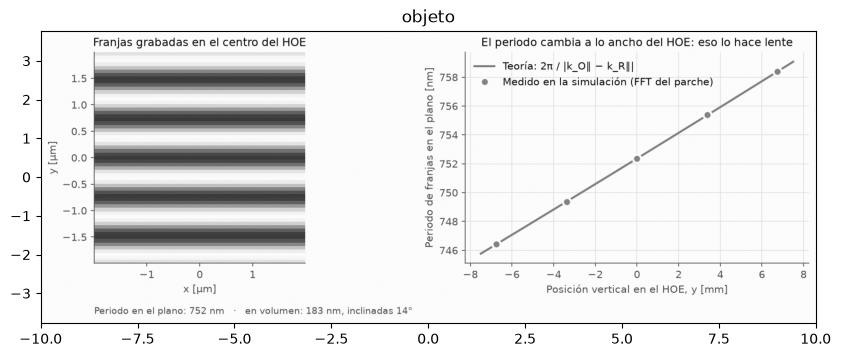

In [13]:
foto = plt.imread(archivo)[:,:,:3].mean(axis=2)
foto = zoom(foto, alto_px/foto.shape[0], order=1)
alto, ancho = foto.shape
rel = alto/ancho
print('pixeles:', alto, 'x', ancho)
plt.figure(figsize=(10, 4))
plt.imshow(foto, cmap='gray', vmin=0, vmax=1, extent=[-h_obj, h_obj, -h_obj*rel, h_obj*rel])
plt.title('objeto'); plt.show()

## Trazado de rayos por lotes

Todo se queda en la GPU: cada pixel lanza `n` rayos a puntos al azar de la pupila y se va sumando el brillo que cae en cada cuadrito de la pantalla.

In [14]:
import time

hx, hy = torch.meshgrid(torch.linspace(-1, 1, ancho, device=dev),
                        torch.linspace(rel, -rel, alto, device=dev), indexing='xy')
hx, hy = hx.ravel(), hy.ravel()
b = torch.tensor(foto.ravel(), device=dev, dtype=torch.float32)

# tamaño de la pantalla: dónde cae el borde del objeto (rayo principal)
z = torch.zeros(2, device=dev)
lente_foto.trace_generic(Hx=torch.tensor([-1., 1.], device=dev), Hy=z, Px=z, Py=z, wavelength=0.55)
xm = float(lente_foto.surfaces.x[-1].abs().max())*1.05
ym = xm*rel

suma = torch.zeros(alto*ancho, device=dev)
cuenta = torch.zeros(alto*ancho, device=dev)
g = torch.Generator(device=dev).manual_seed(0)
total = hx.numel()*n

t0 = time.time()
for i in range(0, total, lote):
    idx = torch.arange(i, min(i+lote, total), device=dev) // n       # a qué pixel pertenece cada rayo
    r = torch.rand(idx.numel(), device=dev, generator=g).sqrt()      # punto al azar en la pupila
    a = 2*torch.pi*torch.rand(idx.numel(), device=dev, generator=g)
    lente_foto.trace_generic(Hx=hx[idx], Hy=hy[idx], Px=r*torch.cos(a), Py=r*torch.sin(a), wavelength=0.55)
    x, y = lente_foto.surfaces.x[-1], lente_foto.surfaces.y[-1]      # dónde pegó cada rayo en la pantalla

    j = ((x + xm)/(2*xm)*ancho).floor().long()                       # columna del cuadrito
    k = ((y + ym)/(2*ym)*alto).floor().long()                        # fila del cuadrito
    ok = (j >= 0) & (j < ancho) & (k >= 0) & (k < alto)
    p = k[ok]*ancho + j[ok]
    suma   += torch.bincount(p, weights=b[idx][ok], minlength=alto*ancho)   # brillo total por cuadrito
    cuenta += torch.bincount(p, minlength=alto*ancho)                       # cuántos rayos por cuadrito
if dev == 'cuda': torch.cuda.synchronize()

imagen = torch.where(cuenta > 0, suma/cuenta.clamp(min=1), torch.nan).reshape(alto, ancho).cpu().numpy()
print(f'rayos: {total:,}   tiempo: {time.time()-t0:.1f} s')
if dev == 'cuda': print('memoria GPU usada:', torch.cuda.max_memory_allocated()//2**20, 'MB')

rayos: 47,979,400   tiempo: 2.5 s
memoria GPU usada: 332 MB


## Resultado

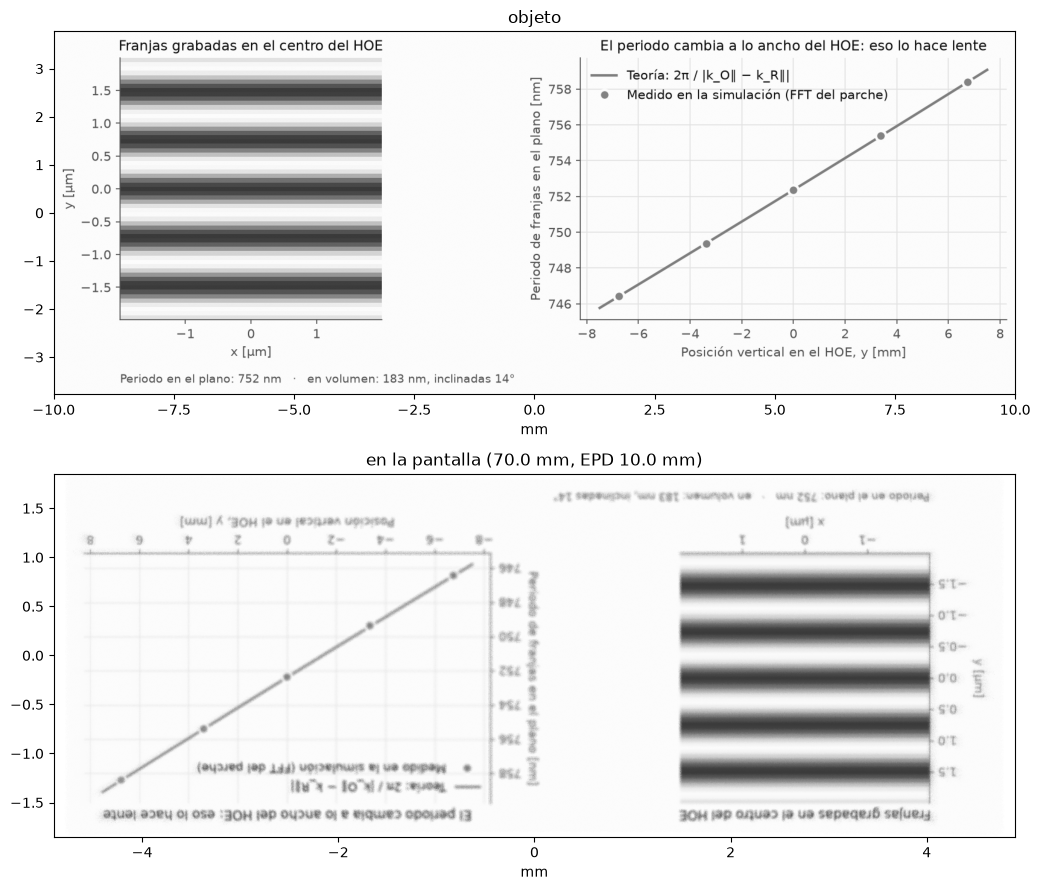

In [15]:
fig, ax = plt.subplots(2, 1, figsize=(11, 9))
ax[0].imshow(foto, cmap='gray', vmin=0, vmax=1, extent=[-h_obj, h_obj, -h_obj*rel, h_obj*rel])
ax[0].set_title('objeto'); ax[0].set_xlabel('mm')
ax[1].imshow(imagen, cmap='gray', vmin=0, vmax=1, origin='lower', extent=[-xm, xm, -ym, ym])
ax[1].set_title(f'en la pantalla ({pantalla} mm, EPD {EPD} mm)'); ax[1].set_xlabel('mm')
plt.tight_layout(); plt.show()

In [18]:
import vtk
from vtk.util.numpy_support import numpy_to_vtk, vtk_to_numpy
from optiland.visualization import OpticViewer3D

def plano_con_foto(img, x0, x1, y0, y1, z):
    """Rectángulo en el plano z con la imagen img (fila 0 = abajo) pegada como textura."""
    a = np.nan_to_num(img, nan=1.0)
    a = (np.clip(a, 0, 1)*255).astype(np.uint8)
    datos = vtk.vtkImageData(); datos.SetDimensions(a.shape[1], a.shape[0], 1)
    datos.GetPointData().SetScalars(numpy_to_vtk(a.ravel(), deep=True))
    tex = vtk.vtkTexture(); tex.SetInputData(datos); tex.InterpolateOn()
    plano = vtk.vtkPlaneSource()
    plano.SetOrigin(x0, y0, z); plano.SetPoint1(x1, y0, z); plano.SetPoint2(x0, y1, z)
    m = vtk.vtkPolyDataMapper(); m.SetInputConnection(plano.GetOutputPort())
    actor = vtk.vtkActor(); actor.SetMapper(m); actor.SetTexture(tex)
    actor.GetProperty().LightingOff()       # que se vea con su brillo real
    return actor

def escena3D(num_rays=12, ventana=True, azimut=240, elevacion=25, acercar=1.6, tam=(1600, 900)):
    z_obj = float(lente_foto.surfaces[0].geometry.cs.z)
    z_img = float(lente_foto.surfaces[-1].geometry.cs.z)
    # rayos que salen de las esquinas y del centro de la foto
    campos = [(0, 0), (-1, rel), (1, rel), (-1, -rel), (1, -rel)]
    v = OpticViewer3D(lente_foto)
    if not ventana: v.ren_win.SetOffScreenRendering(1)
    inicio = v.iren.Start; v.iren.Start = lambda: None
    v.view(fields=campos, num_rays=num_rays, figsize=tam)
    ren = v.ren_win.GetRenderers().GetFirstRenderer()
    ren.AddActor(plano_con_foto(foto[::-1], -h_obj, h_obj, -h_obj*rel, h_obj*rel, z_obj + 0.05))
    ren.AddActor(plano_con_foto(imagen, -xm, xm, -ym, ym, z_img + 0.05))
    ren.ResetCamera()
    cam = ren.GetActiveCamera(); cam.Azimuth(azimut - 150); cam.Elevation(elevacion); cam.Zoom(acercar)
    v.ren_win.Render()
    if ventana:
        inicio()                             # interactiva: se queda abierta hasta cerrarla
    else:
        w = vtk.vtkWindowToImageFilter(); w.SetInput(v.ren_win); w.Update()
        img = w.GetOutput(); nx, ny, _ = img.GetDimensions()
        pix = vtk_to_numpy(img.GetPointData().GetScalars()).reshape(ny, nx, -1)[::-1]
        plt.figure(figsize=(14, 8)); plt.imshow(pix); plt.axis('off'); plt.show()
    v.ren_win.Finalize()

escena3D(ventana=True)      # ventana para rotar y hacer zoom
# escena3D(ventana=False)   # o como imagen dentro del notebook


/home/artis/miniconda3/envs/optica/lib/python3.14/site-packages/optiland/visualization/system/lens.py:58: UserWarning: Lens surfaces overlap.
  self._check_surface_overlap()


In [10]:
lente_foto.draw3D(num_rays=100)

## Liberar memoria de la GPU (opcional)

In [7]:
del suma, cuenta, hx, hy, b
torch.cuda.empty_cache()